# STL-10 Dataset Viewer

## Image Preprocessing

This notebook is a series of experiments on trying to play around and identify how images are transformed so they become useful data and not noise for the underlying model. A good amount of time was spent on image processing to understand how data should be read off the STL-10 binaries. I was also trying to avoid extracting the data to disk and using it.

The code at the very bottom from [Martin Tutek](https://github.com/mttk/STL10) was very helpful in getting started.

### Learning Outcomes

#### `LinearSVC` or `MLPClassifier`

If you are using `LinearSVC` or `MLPClassifier`, you have to skip the `np.transpose`, as it is only for display purpose on the screen, for both the classifiers you need to flatten the images to features before using them.

#### `Neural Network`

### Gotchas

Found this helpful table guide online  
|Library| Expected Shape| Color Order| Notes |
|---|---|---|---|
|OpenCV (cv2)| (H, W, 3)| BGR | If you load an image with OpenCV and display it with Matplotlib, the reds and blues will be swapped.|
|Matplotlib (plt)| (H, W, 3)| RGB | Standard expectation. Expects values 0-255 for uint8 or 0.0-1.0 for floats.|
|Pillow (PIL)| (H, W, 3)| RGB | Use Image.fromarray(arr) to convert a NumPy array into a PIL image.|
|PyTorch (torch)| (3, H, W)| RGB | Deep learning frameworks typically shift channels to the front (Channel-First).|
| Keras | (H, W, 3)  | RGB | Very similar format to OpenCV and Matplotlib. For batches use (batch_size, H, W, 3) |


(height, width, 3)

In [ ]:
# uncomment to install
# %pip install scipy imageio numpy

In [ ]:
import sys
import os, sys, errno
import numpy as np
import matplotlib.pyplot as plt

from imageio import imsave

np.set_printoptions(threshold=sys.maxsize)

print(sys.version_info)

# image shape
HEIGHT = 96
WIDTH = 96
CHANNELS = 3

# size of a single image in bytes
SIZE = HEIGHT * WIDTH * CHANNELS

# path to the binary train file with image data
X_TRAIN_IMAGE = "./stl-10/train_X.bin"

# path to the binary train file with labels
Y_TRAIN_LABEL = "./stl-10/train_y.bin"

sys.version_info(major=3, minor=13, micro=15, releaselevel='final', serial=0)


In [20]:
with open(Y_TRAIN_LABEL, "rb") as f:
    labels = np.fromfile(f, dtype=np.uint8)
    print(len(labels))
    print("First ten labels: ", labels[:10])

5000
First ten labels:  [ 2  6  2  7  4 10  8  5  6  9]


Everything:  (138240000,)
Print first 2 from everything:  [146]
[[[146 146 146]
  [144 144 144]
  [144 144 144]
  [144 144 144]
  [144 144 146]
  [146 146 146]
  [146 146 146]
  [146 147 148]
  [148 148 148]
  [148 144 144]
  [143 140 140]
  [139 140 142]
  [142 142 144]
  [145 145 145]
  [145 143 141]
  [140 139 136]
  [134 132 132]
  [130 126 122]
  [119 116 117]
  [116 114 114]
  [114 115 117]
  [118 124 125]
  [125 127 127]
  [127 127 127]
  [126 125 128]
  [129 130 129]
  [133 133 133]
  [133 133 133]
  [133 133 134]
  [131 129 130]
  [129 129 130]
  [130 134 135]
  [146 146 146]
  [146 146 144]
  [142 142 143]
  [144 144 144]
  [144 144 144]
  [146 147 146]
  [146 147 148]
  [148 148 148]
  [148 148 148]
  [148 148 146]
  [144 141 139]
  [139 140 140]
  [140 140 140]
  [141 140 139]
  [141 139 137]
  [136 135 132]
  [130 128 128]
  [126 122 118]
  [115 113 114]
  [112 111 112]
  [114 116 118]
  [120 122 123]
  [125 125 127]
  [128 127 127]
  [126 125 125]
  [129 131 131]
  [133 1

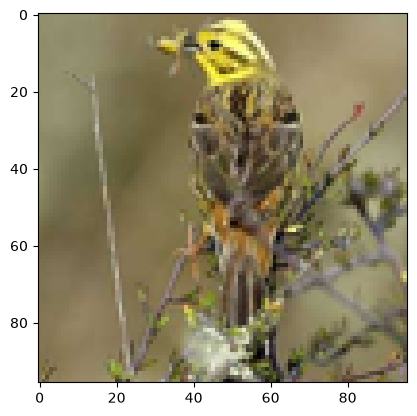

In [ ]:
with open(X_TRAIN_IMAGE, "rb") as f:
    # read whole file in uint8 chunks
    everything = np.fromfile(f, dtype=np.uint8)

    # We force the data into 3x96x96 chunks, since the images are stored in "column-major order", meaning that "the first 96*96 values are the red channel, the next 96*96 are green, and the last are blue. The -1 is since the size of the pictures depends on the input file, and this way numpy determines the size on its own.

    print("Everything: ", everything.shape)
    print("Print first 2 from everything: ", everything[:1])

    images = np.reshape(everything, (-1, HEIGHT, WIDTH, CHANNELS))

    # print("images", images[:1])
    
    images = np.transpose(images, (0, 3, 2, 1))
    # print(image)
    # print("-----------------")

    
    image = np.transpose(image, (2, 1, 0))
    print(image)
    print("-----------------")

    img_last = image

    print(np.array_equal(img_org, img_last))

    plt.imshow(image)
    plt.show()

In [ ]:

images = np.reshape(everything, (-1, 3, 96, 96))

# Now transpose the images into a standard image format
# readable by, for example, matplotlib.imshow
# You might want to comment this line or reverse the shuffle
# if you will use a learning algorithm like CNN, since they like
# their channels separated.
images = np.transpose(images, (0, 3, 2, 1))


image = np.fromfile(image_file, dtype=np.uint8, count=SIZE)
# force into image matrix
image = np.reshape(image, (3, 96, 96))
# transpose to standard format
# You might want to comment this line or reverse the shuffle
# if you will use a learning algorithm like CNN, since they like
# their channels separated.
image = np.transpose(image, (2, 1, 0))


In [ ]:
def read_all_images(path_to_data):
    """
    :param path_to_data: the file containing the binary images from the STL-10 dataset
    :return: an array containing all the images
    """

    with open(path_to_data, "rb") as f:
        # read whole file in uint8 chunks
        everything = np.fromfile(f, dtype=np.uint8)

        # We force the data into 3x96x96 chunks, since the
        # images are stored in "column-major order", meaning
        # that "the first 96*96 values are the red channel,
        # the next 96*96 are green, and the last are blue."
        # The -1 is since the size of the pictures depends
        # on the input file, and this way numpy determines
        # the size on its own.

        images = np.reshape(everything, (-1, 3, 96, 96))

        # Now transpose the images into a standard image format
        # readable by, for example, matplotlib.imshow
        # You might want to comment this line or reverse the shuffle
        # if you will use a learning algorithm like CNN, since they like
        # their channels separated.
        images = np.transpose(images, (0, 3, 2, 1))
        return images


def read_single_image(image_file):
    """
    CAREFUL! - this method uses a file as input instead of the path - so the
    position of the reader will be remembered outside of context of this method.
    :param image_file: the open file containing the images
    :return: a single image
    """
    # read a single image, count determines the number of uint8's to read
    image = np.fromfile(image_file, dtype=np.uint8, count=SIZE)
    # force into image matrix
    image = np.reshape(image, (3, 96, 96))
    # transpose to standard format
    # You might want to comment this line or reverse the shuffle
    # if you will use a learning algorithm like CNN, since they like
    # their channels separated.
    image = np.transpose(image, (2, 1, 0))
    return image


def plot_image(image):
    """
    :param image: the image to be plotted in a 3-D matrix format
    :return: None
    """
    plt.imshow(image)
    plt.show()


def save_image(image, name):
    imsave(uri="%s.png" % name, im=image)


def save_images(images, labels):
    print("Saving images to disk")
    i = 0
    for image in images:
        label = labels[i]
        directory = "./stl-10/img/" + str(label) + "/"
        try:
            os.makedirs(directory, exist_ok=True)
        except OSError as exc:
            if exc.errno == errno.EEXIST:
                pass
        filename = directory + str(i)
        print(filename)
        save_image(image, filename)
        i = i + 1


with open(X_TRAIN_IMAGE) as f:
    image = read_single_image(f)
    plot_image(image)

    # # test to check if the whole dataset is read correctly
    images = read_all_images(X_TRAIN_IMAGE)
    print(images.shape)

    labels = read_labels(Y_TRAIN_LABEL)
    print(labels.shape)

    # # save images to disk
    # save_images(images, labels)